# A Transformer-Based Approach for Raw EEG Classification

### 1. Setup and Imports

Import necessary libraries and set up the environment.



In [2]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

In [3]:
import numpy as np
from pathlib import Path
import re
from datapreprocessing import EEGpreprocessing, EEGDataset
from models import ScaledDotProductAttention, MultiHeadAttention, FeedForward, TransformerLayer, STrans, S_CTrans_Full, MyEEGTransformer,MyEEGTransformerconmiaroba
from train import EarlyStopper, EEGTrainer
from nuovimodels import ScaledDotProductAttention, MultiHeadAttention, FeedForward, TransformerLayer, ConvolutionModule, EEGConformer, EEGTransformerConv1D

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Configuration and Hyperparameters

Define all model and training parameters

### 3. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [6]:
DATASET_PATH = Path("/Users/mariasonetto/magistrale/CMPEDA/progetto/code/data/run di interesse")
edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

# Split riproducibile sui SOGGETTI (Test set isolato)
np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")

File EDF for Train/Validation: 294
File EDF for TEST: 33


Apply preprocessing  #momontaneamente lo faccio solo sul train/val perchè non sono sicura vada fatto sul test, riparlarne con luca

In [7]:
X_raw_list = []
y_list = []
subject_ids_list = []

for rec in train_val_records:
    file_path = rec['path']
    subj_id = rec['subject_id']

    raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    if len(epochs_mne) == 0:
        continue
    
    # Estraiamo i dati grezzi delle epoche (senza normalizzazione qui!)
    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_epochs, n_channels, time_steps)

    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    labels = np.zeros(len(y), dtype=np.int64)
    labels[y == event_id['Left']] = 0
    labels[y == event_id['Right']] = 1

    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))



Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad

/var/folders/nr/r5tnf6151z9__820k8ns469h0000gn/T/ipykernel_7451/1357558177.py:9: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)
/var/folders/nr/r5tnf6151z9__820k8ns469h0000gn/T/ipykernel_7451/1357558177.py:9: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)
/var/folders/nr/r5tnf6151z9__820k8ns469h0000gn/T/ipykernel_7451/1357558177.py:9: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)


15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
1 bad epochs dropped
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
1 bad epochs dropped
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
1 bad epochs dropped
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not s

Convert to PyTorch tensors

In [8]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Dimensioni X_train_val grezzo: {X_training_validation_raw.shape}")
print(f"Dimensioni y_train_val: {y_training_validation.shape}")
print("Distribuzione etichette:", np.unique(y_training_validation, return_counts=True))

Dimensioni X_train_val grezzo: (4402, 64, 641)
Dimensioni y_train_val: (4402,)
Distribuzione etichette: (array([0, 1]), array([2203, 2199]))


### Cross-Individual 3-Fold Cross-Validation and Random grid search to tuning hyperparameters

Provo a caso

In [5]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

param_grid = {
    'lr': [1e-3],
    'dropout': [0.4],
    'weight_decay': [1e-3],
}

NUM_TRIALS = 1

best_overall_acc = 0.0
best_overall_params = None

best_train_losses_history = None
best_val_losses_history = None
best_val_accs_history = None

# ==========================================
# 4. RANDOM SEARCH + GROUP K-FOLD CON NORMALIZZAZIONE PER-CANALE CORRETTA
# ==========================================
for trial in range(NUM_TRIALS):
    print(f'\n>>> RANDOM SEARCH - TENTATIVO {trial + 1}/{NUM_TRIALS} <<<\n')

    sampled_params = {key: random.choice(values) for key, values in param_grid.items()}
    print(f'Parametri testati: {sampled_params}')

    best_accuracies_per_fold = []
    trial_train_losses = []
    trial_val_losses = []
    trial_val_accs = []

    gkf = GroupKFold(n_splits=5)

    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        
        # A. Dividiamo i dati grezzi in base al fold
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        # B. CALCOLO MEDIA E STD PER-CANALE ESCLUSIVAMENTE SUL TRAINING SET
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
        epsilon = 1e-8
        alpha = 0.01

        # C. NORMALIZZAZIONE + RUMORE (DATA AUGMENTATION) SOLO SUL TRAIN
        X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
        noise = alpha * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise

        # D. NORMALIZZAZIONE PURA SUL VAL SET (Usando media e std del TRAIN, SENZA rumore!)
        X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

        # E. Creazione Dataset e DataLoader PyTorch
        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)

        train_loader =DataLoader(train_dataset, batch_size=64, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

        # Inizializziamo il modello all'interno del fold
        model = EEGConformer(
            num_channels=64, time_steps=641, d_model=32, 
            nhead=4, num_layers=1, d_ff=128, dropout=0.4, num_classes=2
        ).to(device)
        
        optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)
        criterion = nn.CrossEntropyLoss()

        print(f"--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1} (150 Epoche) ---")

        # Liste di supporto per tracciare le metriche di questo fold
        train_losses = []
        val_losses = []
        val_accuracies = []

        for epoch in range(30):
            # --- TRAINING ---
            model.train()
            train_loss = 0.0
            train_correct = 0
            train_total = 0
            
            for batch_inputs, batch_labels in train_loader:
                batch_inputs = batch_inputs.to(device)
                batch_labels = batch_labels.to(device)
                
                optimizer.zero_grad()
                outputs, _ = model(batch_inputs)
                loss = criterion(outputs, batch_labels)
                
                loss.backward()
                optimizer.step()
                
                train_loss += loss.item() * batch_inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                train_total += batch_labels.size(0)
                train_correct += (predicted == batch_labels).sum().item()
                
            epoch_train_loss = train_loss / train_total
            epoch_train_acc = train_correct / train_total
            
            # --- VALIDAZIONE ---
            model.eval()
            val_loss = 0.0
            val_correct = 0
            val_total = 0
            
            with torch.no_grad():
                for val_inputs, val_labels in val_loader:
                    val_inputs = val_inputs.to(device)
                    val_labels = val_labels.to(device)
                    
                    val_outputs, _ = model(val_inputs)
                    v_loss = criterion(val_outputs, val_labels)
                    
                    val_loss += v_loss.item() * val_inputs.size(0)
                    _, val_predicted = torch.max(val_outputs, 1)
                    val_total += val_labels.size(0)
                    val_correct += (val_predicted == val_labels).sum().item()
                    
            epoch_val_loss = val_loss / val_total
            epoch_val_acc = val_correct / val_total
            
            # Salviamo nelle liste per il plot
            train_losses.append(epoch_train_loss)
            val_losses.append(epoch_val_loss)
            val_accuracies.append(epoch_val_acc)
            
            print(f"Epoca {epoch+1:3d} | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc*100:6.2f}% || Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc*100:6.2f}%")

        # ==========================================
        # PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
        # ==========================================
        plt.figure(figsize=(14, 5))

        # Pannello 1: Loss
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
        plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
        plt.title(f'Andamento della Loss - Fold {fold + 1}\n(MyEEGTransformer)')
        plt.xlabel('Epoche')
        plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
        plt.legend()
        plt.grid(True, linestyle=':')

        # Pannello 2: Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
        plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
        plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
        plt.xlabel('Epoche')
        plt.ylabel('Accuracy')
        plt.ylim(0.0, 1.0)
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.tight_layout()
        plt.show()

        break # Ci fermiamo dopo il primo fold per questa verifica

🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)

>>> RANDOM SEARCH - TENTATIVO 1/1 <<<

Parametri testati: {'lr': 0.001, 'dropout': 0.4, 'weight_decay': 0.001}


NameError: name 'X_training_validation_raw' is not defined

In [10]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

param_grid = {
    'lr': [1e-3],
    'dropout': [0.5],
    'weight_decay': [1e-2],
}

NUM_TRIALS = 1

best_overall_acc = 0.0
best_overall_params = None

best_train_losses_history = None
best_val_losses_history = None
best_val_accs_history = None

# ==========================================
# 4. RANDOM SEARCH + GROUP K-FOLD CON NORMALIZZAZIONE PER-CANALE CORRETTA
# ==========================================
for trial in range(NUM_TRIALS):
    print(f'\n>>> RANDOM SEARCH - TENTATIVO {trial + 1}/{NUM_TRIALS} <<<\n')

    sampled_params = {key: random.choice(values) for key, values in param_grid.items()}
    print(f'Parametri testati: {sampled_params}')

    best_accuracies_per_fold = []
    trial_train_losses = []
    trial_val_losses = []
    trial_val_accs = []

    gkf = GroupKFold(n_splits=5)

    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        
        # A. Dividiamo i dati grezzi in base al fold
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        # B. CALCOLO MEDIA E STD PER-CANALE ESCLUSIVAMENTE SUL TRAINING SET
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
        epsilon = 1e-8
        alpha = 0.01

        # C. NORMALIZZAZIONE + RUMORE (DATA AUGMENTATION) SOLO SUL TRAIN
        X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
        noise = alpha * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise

        # D. NORMALIZZAZIONE PURA SUL VAL SET (Usando media e std del TRAIN, SENZA rumore!)
        X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

        # E. Creazione Dataset e DataLoader PyTorch
        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)

        train_loader =DataLoader(train_dataset, batch_size=64, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)


        model = EEGConformer(
            num_channels=64, 
            time_steps=641, 
            d_model=32, 
            nhead=4, 
            num_layers=1, 
            d_ff=128, 
            dropout=0.5, 
            num_classes=2
        ).to(device)

        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
        optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

        # Sfruttiamo il tuo trainer con Early Stopping integrato!
        trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

        # Lancia il training completo (si fermerà da solo quando la val_loss smette di migliorare)
        best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
            train_loader, val_loader, epochs=150
        )

        print(f'Miglior Val Accuracy Fold {fold + 1}: {best_val_acc * 100:.2f}%')

                # ==========================================
        # PLOT DELLE CURVE
        # ==========================================
        plt.figure(figsize=(14, 5))

        # Pannello 1: Loss
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
        plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
        plt.title('Andamento della Loss\n(MyEEGTransformer)')
        plt.xlabel('Epoche')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, linestyle=':')

        # Pannello 2: Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
        plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
        plt.title('Andamento Validation Accuracy')
        plt.xlabel('Epoche')
        plt.ylabel('Accuracy')
        plt.ylim(0.0, 1.0)
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.tight_layout()
        plt.show()

       

🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)

>>> RANDOM SEARCH - TENTATIVO 1/1 <<<

Parametri testati: {'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.01}
Epoch 01/150: train_loss=0.69445, val_loss=0.69425, val_acc=49.83%
Epoch 1: train_loss=0.69445, val_loss=0.69425,  val_accuracies=49.83%
Epoch 02/150: train_loss=0.69390, val_loss=0.69347, val_acc=48.90%
Epoch 2: train_loss=0.69390, val_loss=0.69347,  val_accuracies=48.90%
Epoch 03/150: train_loss=0.69267, val_loss=0.69278, val_acc=51.34%
Epoch 3: train_loss=0.69267, val_loss=0.69278,  val_accuracies=51.34%
Epoch 04/150: train_loss=0.69052, val_loss=0.68994, val_acc=53.89%
Epoch 4: train_loss=0.69052, val_loss=0.68994,  val_accuracies=53.89%
Epoch 05/150: train_loss=0.68299, val_loss=0.68096, val_acc=55.75%
Epoch 5: train_loss=0.68299, val_loss=0.68096,  val_accuracies=55.75%
Epoch 06/150: train_loss=0.68283, val_loss=0.67593, val_acc=55.40%
Epoch 6: train_loss=0.68283, val_loss=0.67593,  val_accuracies=55.40%
Epoch 07/150: train

KeyboardInterrupt: 

In [11]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

param_grid = {
    'lr': [1e-3],
    'dropout': [0.4],
    'weight_decay': [1e-2],
}

NUM_TRIALS = 1

best_overall_acc = 0.0
best_overall_params = None

best_train_losses_history = None
best_val_losses_history = None
best_val_accs_history = None

# ==========================================
# 4. RANDOM SEARCH + GROUP K-FOLD CON NORMALIZZAZIONE PER-CANALE CORRETTA
# ==========================================
for trial in range(NUM_TRIALS):
    print(f'\n>>> RANDOM SEARCH - TENTATIVO {trial + 1}/{NUM_TRIALS} <<<\n')

    sampled_params = {key: random.choice(values) for key, values in param_grid.items()}
    print(f'Parametri testati: {sampled_params}')

    best_accuracies_per_fold = []
    trial_train_losses = []
    trial_val_losses = []
    trial_val_accs = []

    gkf = GroupKFold(n_splits=5)

    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        
        # A. Dividiamo i dati grezzi in base al fold
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        # B. CALCOLO MEDIA E STD PER-CANALE ESCLUSIVAMENTE SUL TRAINING SET
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
        epsilon = 1e-8
        alpha = 0.01

        # C. NORMALIZZAZIONE + RUMORE (DATA AUGMENTATION) SOLO SUL TRAIN
        X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
        noise = alpha * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise

        # D. NORMALIZZAZIONE PURA SUL VAL SET (Usando media e std del TRAIN, SENZA rumore!)
        X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

        # E. Creazione Dataset e DataLoader PyTorch
        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)

        train_loader =DataLoader(train_dataset, batch_size=64, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)


        model = EEGConformer(
            num_channels=64, 
            time_steps=641, 
            d_model=32, 
            nhead=4, 
            num_layers=1, 
            d_ff=128, 
            dropout=0.5, 
            num_classes=2
        ).to(device)

        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
        optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

        # Sfruttiamo il tuo trainer con Early Stopping integrato!
        trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

        # Lancia il training completo (si fermerà da solo quando la val_loss smette di migliorare)
        best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
            train_loader, val_loader, epochs=40
        )

        print(f'Miglior Val Accuracy Fold {fold + 1}: {best_val_acc * 100:.2f}%')

                # ==========================================
        # PLOT DELLE CURVE
        # ==========================================
        plt.figure(figsize=(14, 5))

        # Pannello 1: Loss
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
        plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
        plt.title('Andamento della Loss\n(MyEEGTransformer)')
        plt.xlabel('Epoche')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, linestyle=':')

        # Pannello 2: Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
        plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
        plt.title('Andamento Validation Accuracy')
        plt.xlabel('Epoche')
        plt.ylabel('Accuracy')
        plt.ylim(0.0, 1.0)
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.tight_layout()
        plt.show()

       

🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)

>>> RANDOM SEARCH - TENTATIVO 1/1 <<<

Parametri testati: {'lr': 0.001, 'dropout': 0.4, 'weight_decay': 0.01}
Epoch 01/40: train_loss=0.69631, val_loss=0.69282, val_acc=50.17%
Epoch 1: train_loss=0.69631, val_loss=0.69282,  val_accuracies=50.17%
Epoch 02/40: train_loss=0.69415, val_loss=0.69294, val_acc=49.94%
Epoch 2: train_loss=0.69415, val_loss=0.69294,  val_accuracies=49.94%


KeyboardInterrupt: 

### 4. Model Definitions

Instantiate the Transformer-based models: s-Trans, t-Trans.


🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)

>>> RANDOM SEARCH - TENTATIVO 1/1 <<<

Parametri testati: {'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.01}
Epoch 01/40: train_loss=0.70480, val_loss=0.69297, val_acc=50.06%
Epoch 1: train_loss=0.70480, val_loss=0.69297,  val_accuracies=50.06%
Epoch 02/40: train_loss=0.69694, val_loss=0.69459, val_acc=50.17%
Epoch 2: train_loss=0.69694, val_loss=0.69459,  val_accuracies=50.17%
Epoch 03/40: train_loss=0.69780, val_loss=0.69538, val_acc=49.83%
Epoch 3: train_loss=0.69780, val_loss=0.69538,  val_accuracies=49.83%
Epoch 04/40: train_loss=0.69391, val_loss=0.69257, val_acc=51.92%
Epoch 4: train_loss=0.69391, val_loss=0.69257,  val_accuracies=51.92%
Epoch 05/40: train_loss=0.69420, val_loss=0.69234, val_acc=51.68%
Epoch 5: train_loss=0.69420, val_loss=0.69234,  val_accuracies=51.68%
Epoch 06/40: train_loss=0.69160, val_loss=0.69129, val_acc=52.26%
Epoch 6: train_loss=0.69160, val_loss=0.69129,  val_accuracies=52.26%
Epoch 07/40: train_loss=0

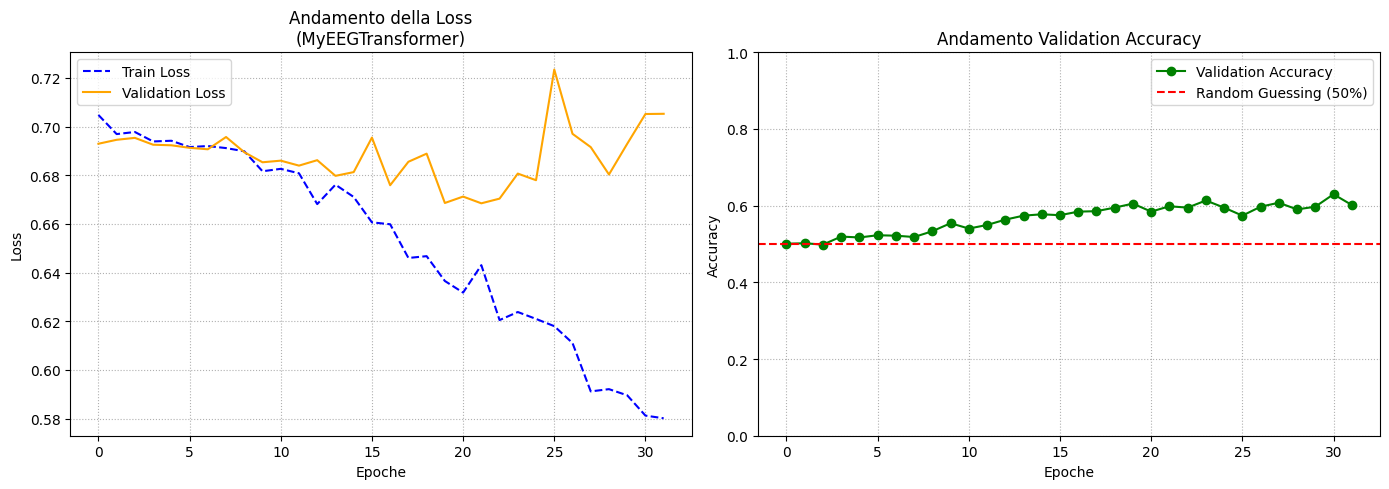

Epoch 01/40: train_loss=0.70945, val_loss=0.69326, val_acc=50.52%
Epoch 1: train_loss=0.70945, val_loss=0.69326,  val_accuracies=50.52%
Epoch 02/40: train_loss=0.69745, val_loss=0.69404, val_acc=50.29%
Epoch 2: train_loss=0.69745, val_loss=0.69404,  val_accuracies=50.29%
Epoch 03/40: train_loss=0.69647, val_loss=0.69302, val_acc=50.17%
Epoch 3: train_loss=0.69647, val_loss=0.69302,  val_accuracies=50.17%
Epoch 04/40: train_loss=0.69490, val_loss=0.69332, val_acc=50.52%
Epoch 4: train_loss=0.69490, val_loss=0.69332,  val_accuracies=50.52%
Epoch 05/40: train_loss=0.69395, val_loss=0.69174, val_acc=53.66%
Epoch 5: train_loss=0.69395, val_loss=0.69174,  val_accuracies=53.66%
Epoch 06/40: train_loss=0.69176, val_loss=0.69164, val_acc=51.22%
Epoch 6: train_loss=0.69176, val_loss=0.69164,  val_accuracies=51.22%
Epoch 07/40: train_loss=0.68582, val_loss=0.69178, val_acc=53.54%
Epoch 7: train_loss=0.68582, val_loss=0.69178,  val_accuracies=53.54%
Epoch 08/40: train_loss=0.69149, val_loss=0.6973

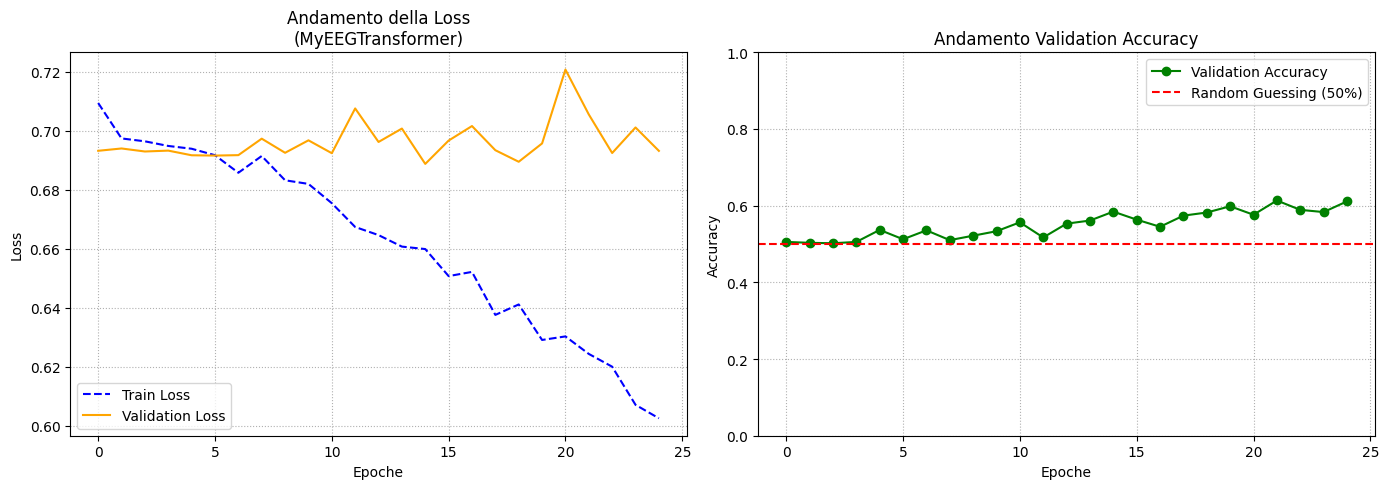

Epoch 01/40: train_loss=0.70498, val_loss=0.69359, val_acc=51.35%
Epoch 1: train_loss=0.70498, val_loss=0.69359,  val_accuracies=51.35%
Epoch 02/40: train_loss=0.69671, val_loss=0.69167, val_acc=53.14%
Epoch 2: train_loss=0.69671, val_loss=0.69167,  val_accuracies=53.14%
Epoch 03/40: train_loss=0.69718, val_loss=0.69177, val_acc=53.81%
Epoch 3: train_loss=0.69718, val_loss=0.69177,  val_accuracies=53.81%
Epoch 04/40: train_loss=0.69540, val_loss=0.69401, val_acc=50.56%
Epoch 4: train_loss=0.69540, val_loss=0.69401,  val_accuracies=50.56%
Epoch 05/40: train_loss=0.69512, val_loss=0.69081, val_acc=56.28%
Epoch 5: train_loss=0.69512, val_loss=0.69081,  val_accuracies=56.28%
Epoch 06/40: train_loss=0.69418, val_loss=0.69206, val_acc=49.89%
Epoch 6: train_loss=0.69418, val_loss=0.69206,  val_accuracies=49.89%
Epoch 07/40: train_loss=0.69448, val_loss=0.68889, val_acc=60.20%
Epoch 7: train_loss=0.69448, val_loss=0.68889,  val_accuracies=60.20%
Epoch 08/40: train_loss=0.69242, val_loss=0.6880

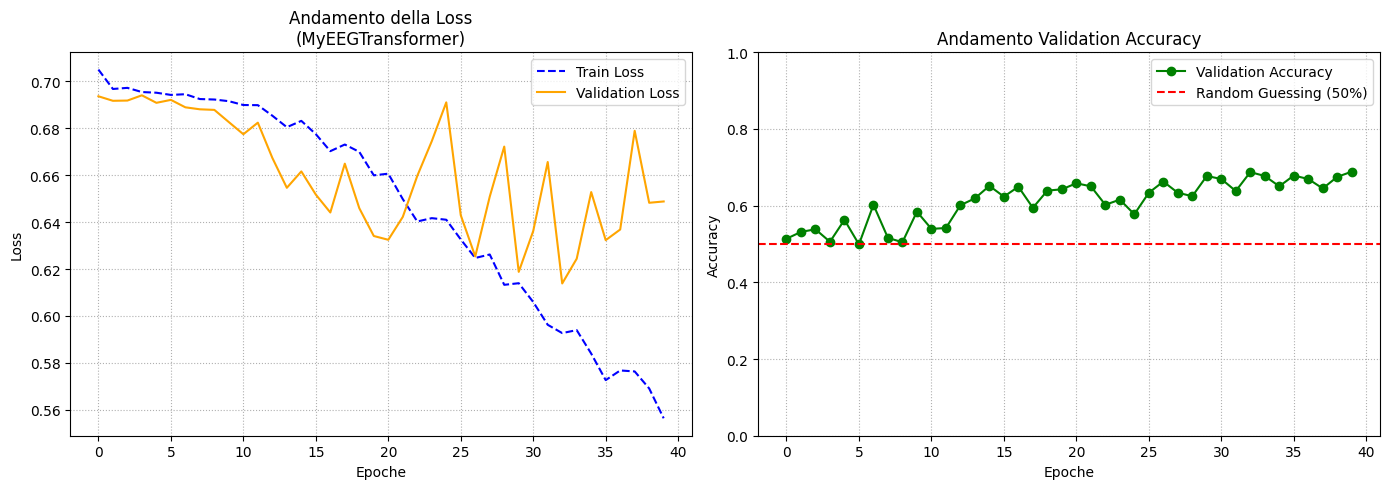

Epoch 01/40: train_loss=0.70104, val_loss=0.69233, val_acc=51.01%
Epoch 1: train_loss=0.70104, val_loss=0.69233,  val_accuracies=51.01%
Epoch 02/40: train_loss=0.69645, val_loss=0.69279, val_acc=49.66%
Epoch 2: train_loss=0.69645, val_loss=0.69279,  val_accuracies=49.66%
Epoch 03/40: train_loss=0.69578, val_loss=0.69199, val_acc=53.13%
Epoch 3: train_loss=0.69578, val_loss=0.69199,  val_accuracies=53.13%
Epoch 04/40: train_loss=0.69544, val_loss=0.69168, val_acc=54.03%
Epoch 4: train_loss=0.69544, val_loss=0.69168,  val_accuracies=54.03%
Epoch 05/40: train_loss=0.69351, val_loss=0.69338, val_acc=51.12%
Epoch 5: train_loss=0.69351, val_loss=0.69338,  val_accuracies=51.12%
Epoch 06/40: train_loss=0.69437, val_loss=0.69116, val_acc=51.57%
Epoch 6: train_loss=0.69437, val_loss=0.69116,  val_accuracies=51.57%
Epoch 07/40: train_loss=0.69233, val_loss=0.69059, val_acc=51.23%
Epoch 7: train_loss=0.69233, val_loss=0.69059,  val_accuracies=51.23%
Epoch 08/40: train_loss=0.69326, val_loss=0.6956

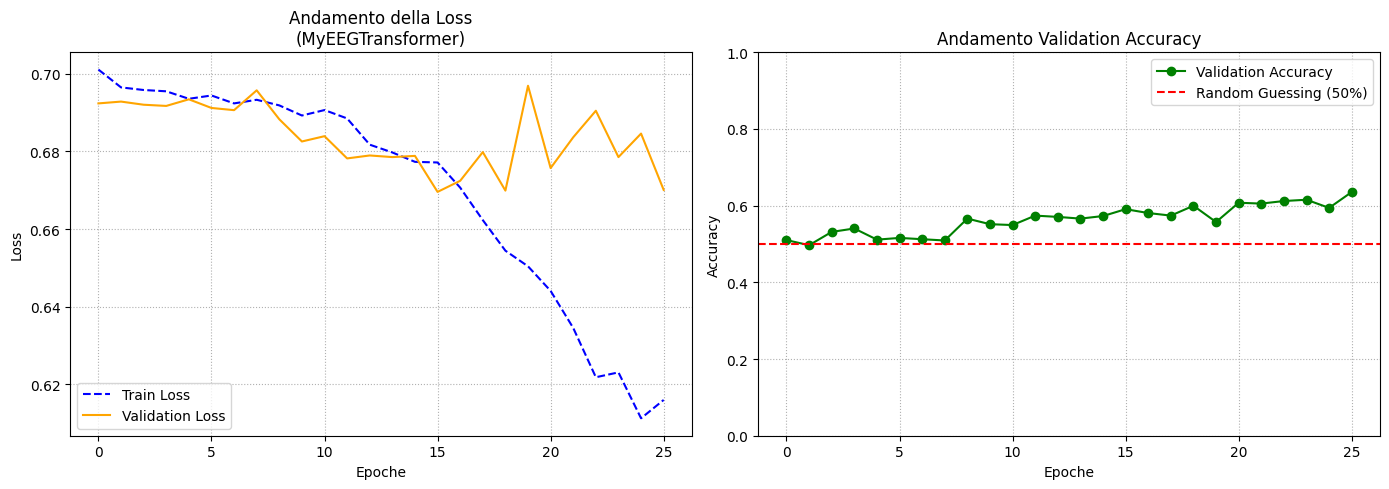

Epoch 01/40: train_loss=0.70258, val_loss=0.69463, val_acc=50.00%
Epoch 1: train_loss=0.70258, val_loss=0.69463,  val_accuracies=50.00%
Epoch 02/40: train_loss=0.69567, val_loss=0.69230, val_acc=52.91%
Epoch 2: train_loss=0.69567, val_loss=0.69230,  val_accuracies=52.91%
Epoch 03/40: train_loss=0.69629, val_loss=0.69188, val_acc=53.02%
Epoch 3: train_loss=0.69629, val_loss=0.69188,  val_accuracies=53.02%
Epoch 04/40: train_loss=0.69353, val_loss=0.69135, val_acc=52.24%
Epoch 4: train_loss=0.69353, val_loss=0.69135,  val_accuracies=52.24%
Epoch 05/40: train_loss=0.69288, val_loss=0.69468, val_acc=50.67%
Epoch 5: train_loss=0.69288, val_loss=0.69468,  val_accuracies=50.67%
Epoch 06/40: train_loss=0.69200, val_loss=0.68975, val_acc=55.15%
Epoch 6: train_loss=0.69200, val_loss=0.68975,  val_accuracies=55.15%
Epoch 07/40: train_loss=0.68701, val_loss=0.68764, val_acc=55.59%
Epoch 7: train_loss=0.68701, val_loss=0.68764,  val_accuracies=55.59%
Epoch 08/40: train_loss=0.68460, val_loss=0.7018

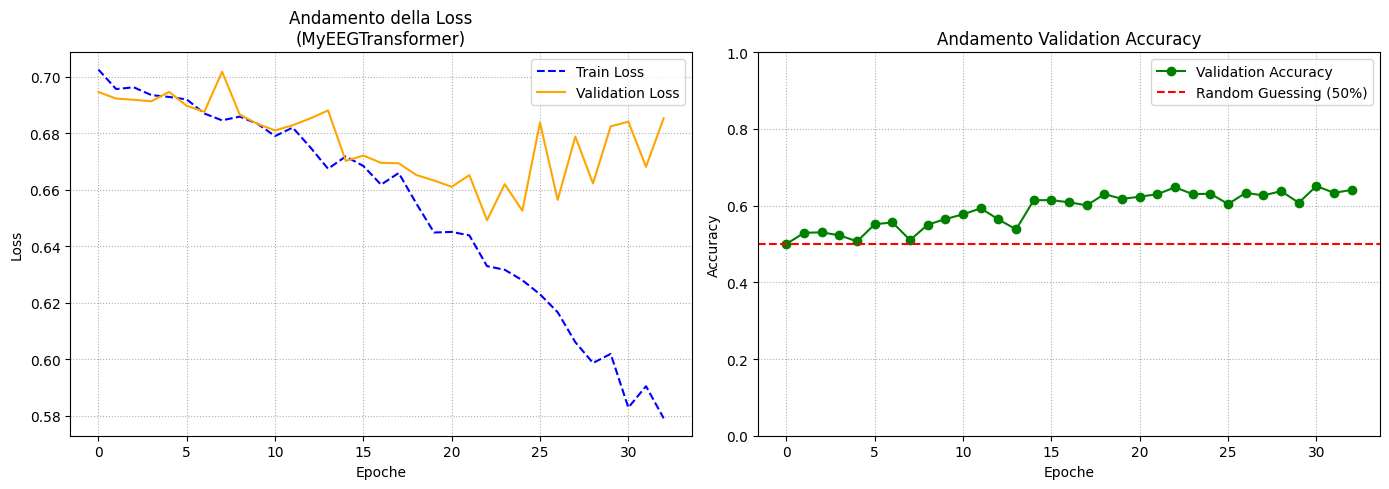

In [12]:


import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

param_grid = {
    'lr': [1e-3],
    'dropout': [0.5],
    'weight_decay': [1e-2],
}

NUM_TRIALS = 1

best_overall_acc = 0.0
best_overall_params = None

best_train_losses_history = None
best_val_losses_history = None
best_val_accs_history = None

# ==========================================
# 4. RANDOM SEARCH + GROUP K-FOLD CON NORMALIZZAZIONE PER-CANALE CORRETTA
# ==========================================
for trial in range(NUM_TRIALS):
    print(f'\n>>> RANDOM SEARCH - TENTATIVO {trial + 1}/{NUM_TRIALS} <<<\n')

    sampled_params = {key: random.choice(values) for key, values in param_grid.items()}
    print(f'Parametri testati: {sampled_params}')

    best_accuracies_per_fold = []
    trial_train_losses = []
    trial_val_losses = []
    trial_val_accs = []

    gkf = GroupKFold(n_splits=5)

    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        
        # A. Dividiamo i dati grezzi in base al fold
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        # B. CALCOLO MEDIA E STD PER-CANALE ESCLUSIVAMENTE SUL TRAINING SET
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
        epsilon = 1e-8
        alpha = 0.01

        # C. NORMALIZZAZIONE + RUMORE (DATA AUGMENTATION) SOLO SUL TRAIN
        X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
        noise = alpha * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise

        # D. NORMALIZZAZIONE PURA SUL VAL SET (Usando media e std del TRAIN, SENZA rumore!)
        X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

        # E. Creazione Dataset e DataLoader PyTorch
        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)

        train_loader =DataLoader(train_dataset, batch_size=64, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)


        model = EEGTransformerConv1D(
            num_channels=64, 
            time_steps=641, 
            d_model=32, 
            nhead=4, 
            num_layers=1, 
            d_ff=128, 
            dropout=0.5, 
            num_classes=2
        ).to(device)

        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
        optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

        # Sfruttiamo il tuo trainer con Early Stopping integrato!
        trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

        # Lancia il training completo (si fermerà da solo quando la val_loss smette di migliorare)
        best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
            train_loader, val_loader, epochs=40
        )

        print(f'Miglior Val Accuracy Fold {fold + 1}: {best_val_acc * 100:.2f}%')

                # ==========================================
        # PLOT DELLE CURVE
        # ==========================================
        plt.figure(figsize=(14, 5))

        # Pannello 1: Loss
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
        plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
        plt.title('Andamento della Loss\n(MyEEGTransformer)')
        plt.xlabel('Epoche')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, linestyle=':')

        # Pannello 2: Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
        plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
        plt.title('Andamento Validation Accuracy')
        plt.xlabel('Epoche')
        plt.ylabel('Accuracy')
        plt.ylim(0.0, 1.0)
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.tight_layout()
        plt.show()

       

🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)

>>> RANDOM SEARCH - TENTATIVO 1/1 <<<

Parametri testati: {'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.01}

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 ---
Epoch 01/40: train_loss=0.70535, val_loss=0.69381, val_acc=50.29%
Epoch 1: train_loss=0.70535, val_loss=0.69381,  val_accuracies=50.29%
Epoch 02/40: train_loss=0.69611, val_loss=0.69281, val_acc=50.75%
Epoch 2: train_loss=0.69611, val_loss=0.69281,  val_accuracies=50.75%
Epoch 03/40: train_loss=0.69611, val_loss=0.69269, val_acc=48.78%
Epoch 3: train_loss=0.69611, val_loss=0.69269,  val_accuracies=48.78%
Epoch 04/40: train_loss=0.69620, val_loss=0.69394, val_acc=49.83%
Epoch 4: train_loss=0.69620, val_loss=0.69394,  val_accuracies=49.83%
Epoch 05/40: train_loss=0.69530, val_loss=0.69227, val_acc=51.68%
Epoch 5: train_loss=0.69530, val_loss=0.69227,  val_accuracies=51.68%
Epoch 06/40: train_loss=0.69511, val_loss=0.69184, val_acc=51.57%
Epoch 6: train_loss=0.69511, val_loss=0.69184

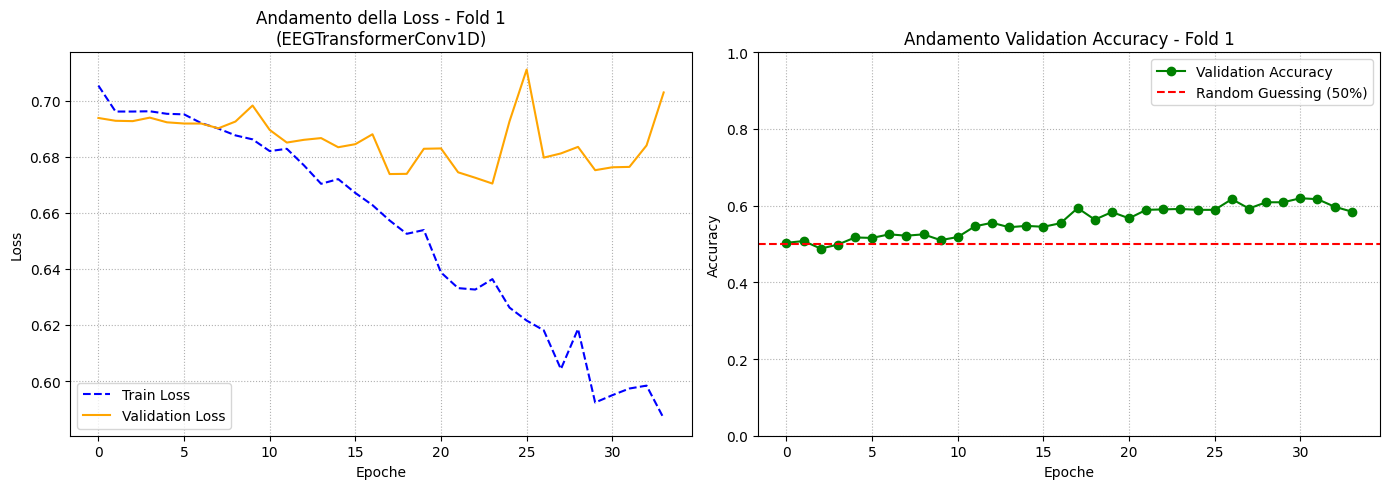


--- INIZIO TRAINING & VALIDAZIONE - FOLD 2/5 ---
Epoch 01/40: train_loss=0.70594, val_loss=0.69362, val_acc=49.25%
Epoch 1: train_loss=0.70594, val_loss=0.69362,  val_accuracies=49.25%
Epoch 02/40: train_loss=0.69837, val_loss=0.69298, val_acc=50.64%
Epoch 2: train_loss=0.69837, val_loss=0.69298,  val_accuracies=50.64%
Epoch 03/40: train_loss=0.69656, val_loss=0.69390, val_acc=49.83%
Epoch 3: train_loss=0.69656, val_loss=0.69390,  val_accuracies=49.83%
Epoch 04/40: train_loss=0.69572, val_loss=0.69286, val_acc=50.41%
Epoch 4: train_loss=0.69572, val_loss=0.69286,  val_accuracies=50.41%
Epoch 05/40: train_loss=0.69221, val_loss=0.69520, val_acc=50.41%
Epoch 5: train_loss=0.69221, val_loss=0.69520,  val_accuracies=50.41%
Epoch 06/40: train_loss=0.69187, val_loss=0.69151, val_acc=52.26%
Epoch 6: train_loss=0.69187, val_loss=0.69151,  val_accuracies=52.26%
Epoch 07/40: train_loss=0.68742, val_loss=0.69026, val_acc=52.85%
Epoch 7: train_loss=0.68742, val_loss=0.69026,  val_accuracies=52.85

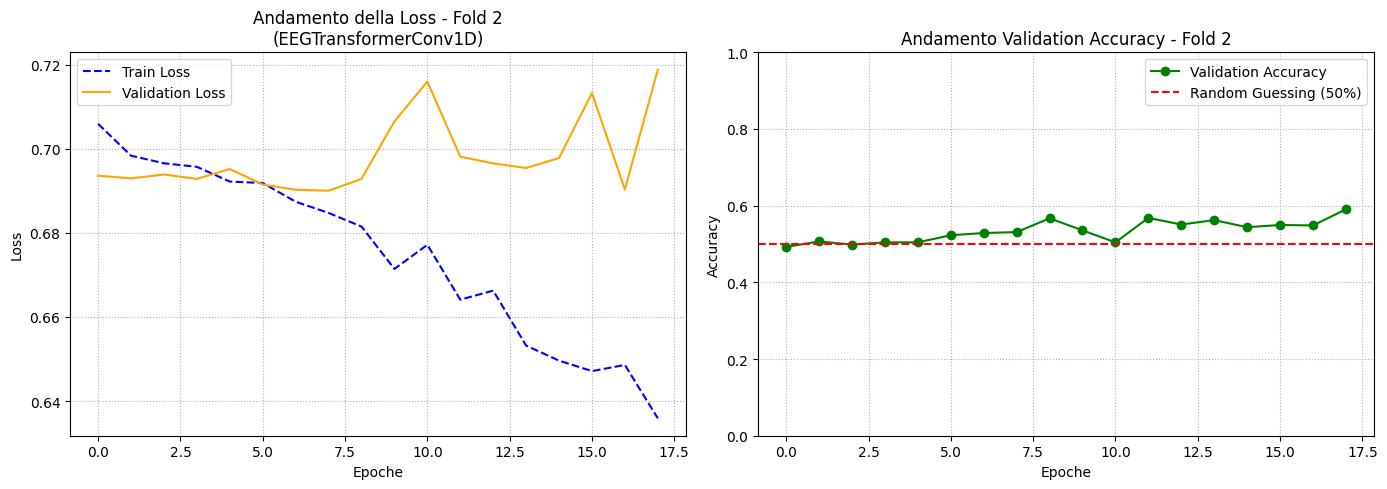


--- INIZIO TRAINING & VALIDAZIONE - FOLD 3/5 ---
Epoch 01/40: train_loss=0.71246, val_loss=0.69279, val_acc=50.45%
Epoch 1: train_loss=0.71246, val_loss=0.69279,  val_accuracies=50.45%
Epoch 02/40: train_loss=0.69773, val_loss=0.69233, val_acc=50.11%
Epoch 2: train_loss=0.69773, val_loss=0.69233,  val_accuracies=50.11%
Epoch 03/40: train_loss=0.69760, val_loss=0.69209, val_acc=50.56%
Epoch 3: train_loss=0.69760, val_loss=0.69209,  val_accuracies=50.56%
Epoch 04/40: train_loss=0.69633, val_loss=0.69229, val_acc=50.90%
Epoch 4: train_loss=0.69633, val_loss=0.69229,  val_accuracies=50.90%
Epoch 05/40: train_loss=0.69502, val_loss=0.69140, val_acc=53.59%
Epoch 5: train_loss=0.69502, val_loss=0.69140,  val_accuracies=53.59%
Epoch 06/40: train_loss=0.69562, val_loss=0.69004, val_acc=55.61%
Epoch 6: train_loss=0.69562, val_loss=0.69004,  val_accuracies=55.61%
Epoch 07/40: train_loss=0.69454, val_loss=0.68981, val_acc=50.56%
Epoch 7: train_loss=0.69454, val_loss=0.68981,  val_accuracies=50.56

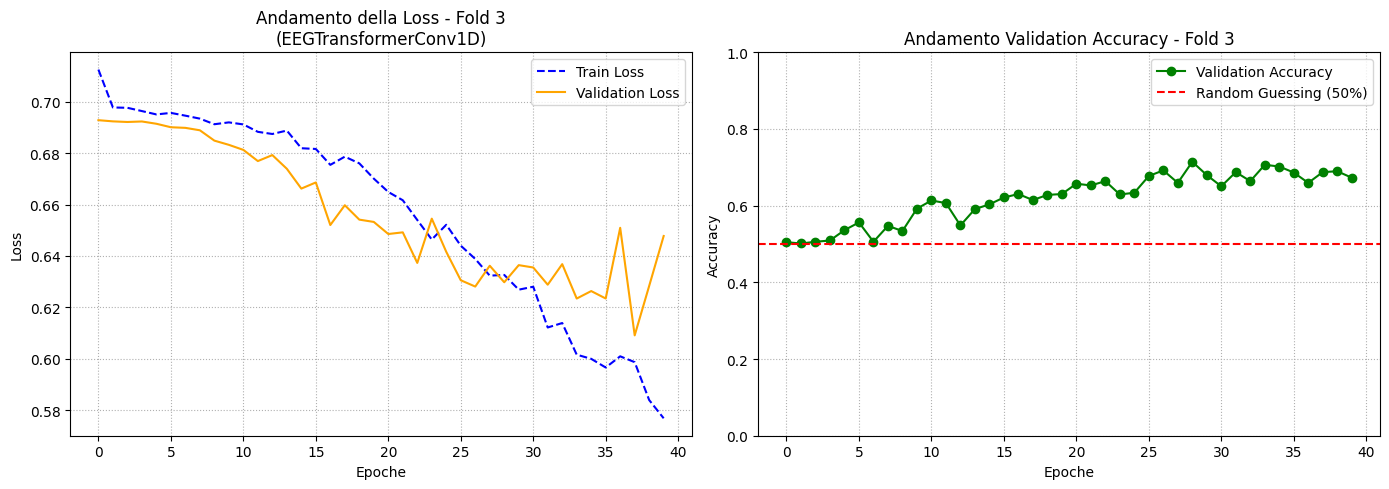


--- INIZIO TRAINING & VALIDAZIONE - FOLD 4/5 ---
Epoch 01/40: train_loss=0.70464, val_loss=0.69470, val_acc=49.55%
Epoch 1: train_loss=0.70464, val_loss=0.69470,  val_accuracies=49.55%
Epoch 02/40: train_loss=0.69946, val_loss=0.69233, val_acc=50.34%
Epoch 2: train_loss=0.69946, val_loss=0.69233,  val_accuracies=50.34%
Epoch 03/40: train_loss=0.69687, val_loss=0.69393, val_acc=51.12%
Epoch 3: train_loss=0.69687, val_loss=0.69393,  val_accuracies=51.12%
Epoch 04/40: train_loss=0.69616, val_loss=0.69195, val_acc=52.35%
Epoch 4: train_loss=0.69616, val_loss=0.69195,  val_accuracies=52.35%
Epoch 05/40: train_loss=0.69585, val_loss=0.69156, val_acc=53.36%
Epoch 5: train_loss=0.69585, val_loss=0.69156,  val_accuracies=53.36%
Epoch 06/40: train_loss=0.69360, val_loss=0.69138, val_acc=50.67%
Epoch 6: train_loss=0.69360, val_loss=0.69138,  val_accuracies=50.67%
Epoch 07/40: train_loss=0.69323, val_loss=0.68980, val_acc=54.03%
Epoch 7: train_loss=0.69323, val_loss=0.68980,  val_accuracies=54.03

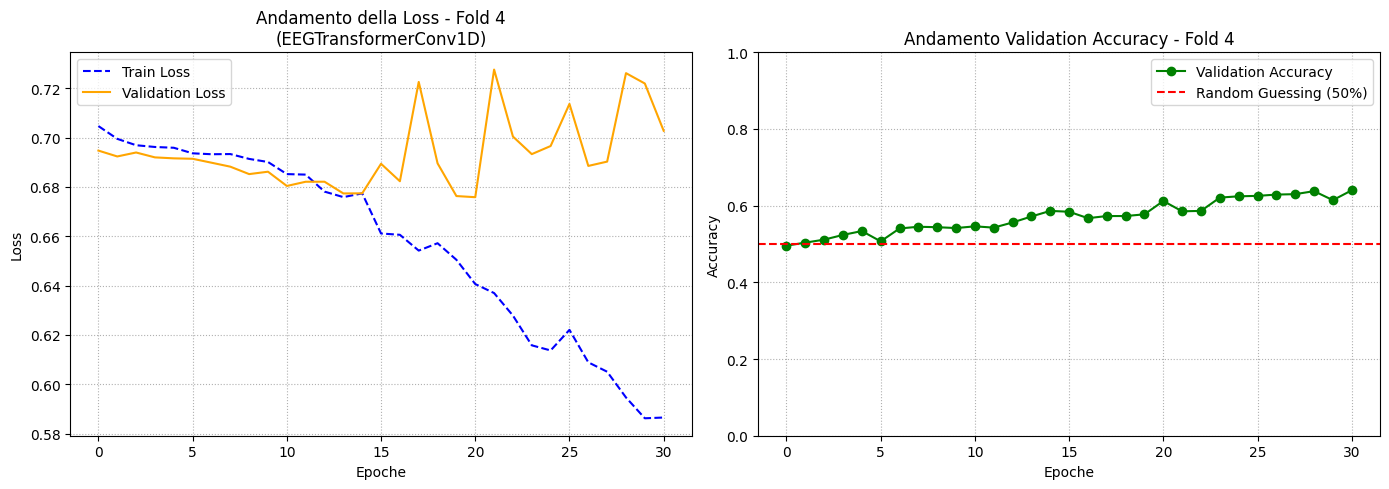


--- INIZIO TRAINING & VALIDAZIONE - FOLD 5/5 ---
Epoch 01/40: train_loss=0.70244, val_loss=0.69470, val_acc=50.00%
Epoch 1: train_loss=0.70244, val_loss=0.69470,  val_accuracies=50.00%
Epoch 02/40: train_loss=0.69795, val_loss=0.69285, val_acc=51.34%
Epoch 2: train_loss=0.69795, val_loss=0.69285,  val_accuracies=51.34%
Epoch 03/40: train_loss=0.69351, val_loss=0.69310, val_acc=50.11%
Epoch 3: train_loss=0.69351, val_loss=0.69310,  val_accuracies=50.11%
Epoch 04/40: train_loss=0.69514, val_loss=0.69429, val_acc=50.22%
Epoch 4: train_loss=0.69514, val_loss=0.69429,  val_accuracies=50.22%
Epoch 05/40: train_loss=0.69107, val_loss=0.69113, val_acc=52.80%
Epoch 5: train_loss=0.69107, val_loss=0.69113,  val_accuracies=52.80%
Epoch 06/40: train_loss=0.69190, val_loss=0.68946, val_acc=55.93%
Epoch 6: train_loss=0.69190, val_loss=0.68946,  val_accuracies=55.93%
Epoch 07/40: train_loss=0.68963, val_loss=0.68931, val_acc=53.47%
Epoch 7: train_loss=0.68963, val_loss=0.68931,  val_accuracies=53.47

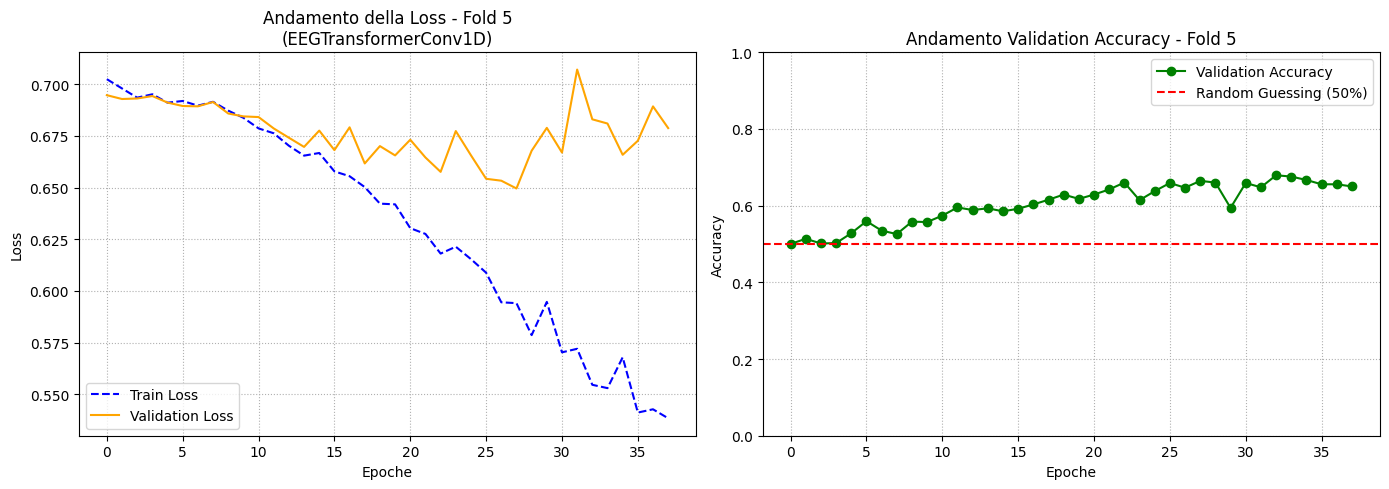


📊 RISULTATI FINALI CROSS-VALIDATION (5 FOLD)
 - Fold 1: 61.90%
 - Fold 2: 59.00%
 - Fold 3: 71.41%
 - Fold 4: 63.98%
 - Fold 5: 67.90%

🎯 Accuracy Media Finale: 64.84% (± 4.38%)


In [13]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

param_grid = {
    'lr': [1e-3],
    'dropout': [0.5],
    'weight_decay': [1e-2],
}

NUM_TRIALS = 1

best_overall_acc = 0.0
all_folds_accuracies = []

# ==========================================
# 4. RANDOM SEARCH + GROUP K-FOLD COMPLETO
# ==========================================
for trial in range(NUM_TRIALS):
    print(f'\n>>> RANDOM SEARCH - TENTATIVO {trial + 1}/{NUM_TRIALS} <<<\n')

    sampled_params = {key: random.choice(values) for key, values in param_grid.items()}
    print(f'Parametri testati: {sampled_params}')

    gkf = GroupKFold(n_splits=5)

    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        
        print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 ---")

        # A. Dividiamo i dati grezzi in base al fold
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        # B. CALCOLO MEDIA E STD PER-CANALE ESCLUSIVAMENTE SUL TRAINING SET
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
        epsilon = 1e-8
        alpha = 0.01

        # C. NORMALIZZAZIONE + RUMORE (DATA AUGMENTATION) SOLO SUL TRAIN
        X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
        noise = alpha * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise

        # D. NORMALIZZAZIONE PURA SUL VAL SET
        X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

        # E. Creazione Dataset e DataLoader PyTorch
        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)

        train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

        # Inizializzazione del modello
        model = EEGTransformerConv1D(
            num_channels=64, 
            time_steps=641, 
            d_model=32, 
            nhead=4, 
            num_layers=1, 
            d_ff=128, 
            dropout=sampled_params['dropout'], 
            num_classes=2
        ).to(device)

        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
        optimizer = optim.AdamW(model.parameters(), lr=sampled_params['lr'], weight_decay=sampled_params['weight_decay'])

        # Trainer con Early Stopping integrato
        trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

        # Lancia il training completo per questo fold
        best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
            train_loader, val_loader, epochs=40
        )

        all_folds_accuracies.append(best_val_acc)
        print(f'✅ Fine Fold {fold + 1} | Miglior Val Accuracy: {best_val_acc * 100:.2f}%')

        # ==========================================
        # PLOT DELLE CURVE PER QUESTO FOLD
        # ==========================================
        plt.figure(figsize=(14, 5))

        # Pannello 1: Loss
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
        plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
        plt.title(f'Andamento della Loss - Fold {fold + 1}\n(EEGTransformerConv1D)')
        plt.xlabel('Epoche')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, linestyle=':')

        # Pannello 2: Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
        plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
        plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
        plt.xlabel('Epoche')
        plt.ylabel('Accuracy')
        plt.ylim(0.0, 1.0)
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.tight_layout()
        plt.show()

# ==========================================
# RIEPILOGO FINALE DELLA CROSS-VALIDATION
# ==========================================
print("\n" + "="*40)
print("📊 RISULTATI FINALI CROSS-VALIDATION (5 FOLD)")
print("="*40)
for i, acc in enumerate(all_folds_accuracies):
    print(f" - Fold {i + 1}: {acc * 100:.2f}%")
print(f"\n🎯 Accuracy Media Finale: {np.mean(all_folds_accuracies) * 100:.2f}% (± {np.std(all_folds_accuracies) * 100:.2f}%)")
print("="*40)

### 5. Training and Evaluation Functions



Implement the training and evaluation loops, including loss function, optimizer, and accuracy calculation. The paper uses Adam optimizer and cross-entropy loss.

### 6. Cross-Individual 5-Fold Cross-Validation



Implement the 5-fold cross-validation strategy as described in the paper. This involves splitting subjects into training and testing sets.

### 7. Positional Embedding Analysis (Visualization)



This section would involve analyzing the impact of different positional embedding methods on model performance, as discussed in the paper. This would be derived from the cross-validation results.

### 8. Attention Weight Visualization




Visualize the attention weights from the Transformer modules, especially for the s-Trans model, to understand the model"s focus on different EEG channels, similar to the topographical analysis in the paper (Fig. 6). This requires mne.viz.plot_topomap and electrode location information.
